# RespiraCidadão: Machine Learning & Modelling (GS 2026.2)

Turma 1TIAPZ1, grupo Perceptron.

- Giovanni Henrique Pereira Hessel (RM 570574)
- Suellen Pereira da Silva (RM 573862)
- Israel Carneiro de Toledo (RM 573854)

## 1. Problema, público e dados

Fumaça de queimada e trânsito pesado sobem o monóxido de carbono (CO) perto de escolas e UBS. Quem sente primeiro são crianças, idosos e quem tem asma ou DPOC. Nosso nó comunitário (ESP32) mede dois sensores de gás de óxido metálico e temperatura/umidade. A pergunta deste notebook: com só essas 4 leituras, dá para prever o nível de risco do ar?

- Base real: UCI Air Quality (De Vito et al., 2008), 9.357 registros horários de uma estação com sensores de óxido metálico (PT08.S1 a S5), analisadores de referência e microclima. Após a limpeza dos códigos -200 ficam 6.941 horas completas.
- Alvo: nível de risco a partir do CO medido pelo analisador de referência, CO(GT). Ele só define o rótulo e nunca entra como entrada.
  - normal: CO(GT) < 1,5 mg/m³
  - atencao: 1,5 a 3,0 mg/m³
  - critico: CO(GT) >= 3,0 mg/m³
- Entradas: as 4 leituras que o ESP32 manda no JSON.

| Coluna UCI | Campo no JSON do ESP32 | Sensor no nó |
|---|---|---|
| PT08.S1(CO) | gas_co | MOx de CO (tipo MQ-7) |
| PT08.S2(NMHC) | gas_voc | MOx de hidrocarbonetos/fumaça (tipo MQ-135) |
| T | temperatura_c | DHT22 |
| RH | umidade_pct | DHT22 |

ODS 3 (saúde), 10 (desigualdades) e 11 (cidades sustentáveis).

In [1]:
import json
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

plt.rcParams.update({"figure.facecolor": "white", "axes.grid": True, "grid.alpha": 0.3})
RISK_COLORS = ["#2E9E5B", "#E0A100", "#ED145B"]

ROOT = Path.cwd().resolve()
if ROOT.name == "ml-modelling":
    ROOT = ROOT.parents[1]

DATA_PATH = ROOT / "data" / "processed" / "air_quality_clean.csv"
OUT_DIR = ROOT / "packages" / "ml-modelling"
CHARTS_DIR = OUT_DIR / "charts"
ARTIFACTS_DIR = OUT_DIR / "artifacts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

# Ordem igual ao JSON do ESP32: gas_co, gas_voc, temperatura_c, umidade_pct
FEATURES = ["PT08.S1(CO)", "PT08.S2(NMHC)", "T", "RH"]
LAB_FEATURES = [
    "PT08.S1(CO)", "C6H6(GT)", "PT08.S2(NMHC)", "NOx(GT)", "PT08.S3(NOx)",
    "NO2(GT)", "PT08.S4(NO2)", "PT08.S5(O3)", "T", "RH", "AH",
]
CLASS_NAMES = ["normal", "atencao", "critico"]
VOC_ATENCAO, VOC_CRITICO = 830.0, 1140.0  # regra offline do ESP32

df = pd.read_csv(DATA_PATH)
df["datahora"] = pd.to_datetime(df["Date"] + " " + df["Time"], format="%d/%m/%Y %H.%M.%S")
print(f"{df.shape[0]} horas, de {df['datahora'].min():%d/%m/%Y} a {df['datahora'].max():%d/%m/%Y}")
df[FEATURES + ["CO(GT)", "nivel_risco"]].head()

6941 horas, de 10/03/2004 a 04/04/2005


,PT08.S1(CO),PT08.S2(NMHC),T,RH,CO(GT),nivel_risco
0,1360.0,1046.0,13.6,48.9,2.6,atencao
1,1292.0,955.0,13.3,47.7,2.0,atencao
2,1402.0,939.0,11.9,54.0,2.2,atencao
3,1376.0,948.0,11.0,60.0,2.2,atencao
4,1272.0,836.0,11.2,59.6,1.6,atencao


## 2. Análise exploratória

Conferimos ausentes, o balanço das classes e se os sensores de campo separam as classes de risco. Se o sensor de fumaça (PT08.S2) não mudasse entre normal e crítico, nem valeria treinar.

Ausentes: 0
nivel_risco
atencao    0.392
normal     0.365
critico    0.244
Name: proportion, dtype: float64
                 mean    std    min     max
PT08.S1(CO)    1119.9  218.7  647.0  2040.0
PT08.S2(NMHC)   958.5  264.1  390.0  2214.0
T                17.8    8.8   -1.9    44.6
RH               48.9   17.4    9.2    88.7


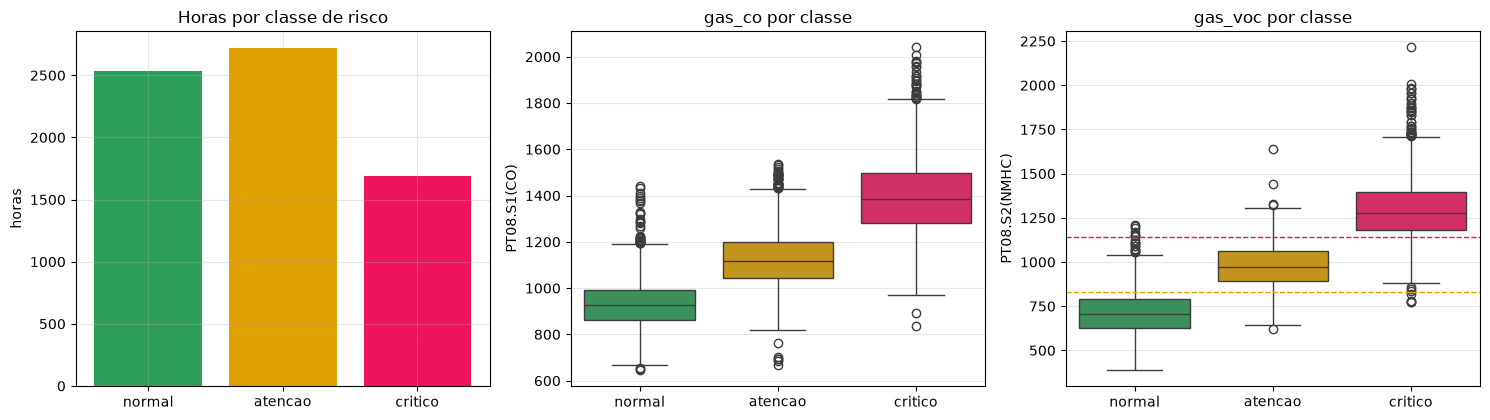

In [2]:
print("Ausentes:", int(df[FEATURES + ["CO(GT)"]].isna().sum().sum()))
print(df["nivel_risco"].value_counts(normalize=True).round(3))
print(df[FEATURES].describe().T[["mean", "std", "min", "max"]].round(1))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
counts = df["nivel_risco"].value_counts().reindex(CLASS_NAMES)
axes[0].bar(counts.index, counts.values, color=RISK_COLORS)
axes[0].set_title("Horas por classe de risco")
axes[0].set_ylabel("horas")
for ax, col, nome in [(axes[1], "PT08.S1(CO)", "gas_co"), (axes[2], "PT08.S2(NMHC)", "gas_voc")]:
    sns.boxplot(data=df, x="nivel_risco", y=col, order=CLASS_NAMES, palette=RISK_COLORS, ax=ax)
    ax.set_title(f"{nome} por classe")
    ax.set_xlabel("")
axes[2].axhline(VOC_ATENCAO, color="#E0A100", ls="--", lw=1)
axes[2].axhline(VOC_CRITICO, color="#ED145B", ls="--", lw=1)
fig.tight_layout()
fig.savefig(CHARTS_DIR / "01_eda_classes_box.png", dpi=150)
plt.show()

As medianas dos dois sensores sobem de normal para crítico, e o de hidrocarbonetos (gas_voc) separa melhor. As linhas tracejadas são os limiares que o ESP32 usa sozinho, sem rede: 830 para atenção e 1140 para crítico. Tiramos esses valores da própria base, buscando o par que maximiza o F1-macro.

## 3. Pré-processamento sem vazamento

- X recebe as 4 leituras de campo e y recebe nivel_risco_id (0, 1, 2).
- Split estratificado 80/20 com random_state=42.
- O StandardScaler fica dentro do Pipeline, então só aprende com os dados de treino de cada fold.

In [3]:
X = df[FEATURES].to_numpy(dtype=np.float32)
y = df["nivel_risco_id"].to_numpy(dtype=np.int64)
idx_train, idx_test = train_test_split(
    np.arange(len(df)), test_size=0.20, random_state=42, stratify=y
)
X_train, X_test, y_train, y_test = X[idx_train], X[idx_test], y[idx_train], y[idx_test]
print(f"Treino: {X_train.shape} | Teste: {X_test.shape}")

Treino: (5552, 4) | Teste: (1389, 4)


## 4. Comparação de algoritmos

A regressão logística é o baseline. Contra ela colocamos KNN, árvore de decisão, Random Forest e Gradient Boosting. Medimos acurácia, F1-macro (as classes não são iguais em tamanho) e o gap entre treino e teste para enxergar overfitting.

In [4]:
def pipe(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])

candidates = {
    "LogisticRegression (baseline)": pipe(LogisticRegression(max_iter=2000, random_state=42)),
    "KNN (k=15)": pipe(KNeighborsClassifier(n_neighbors=15)),
    "DecisionTree (depth=8)": pipe(DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=42)),
    "RandomForest (default)": pipe(RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)),
    "GradientBoosting": pipe(GradientBoostingClassifier(random_state=42)),
}

def score_row(name, model):
    tr, te = model.predict(X_train), model.predict(X_test)
    return {
        "modelo": name,
        "train_acc": round(float(accuracy_score(y_train, tr)), 4),
        "test_acc": round(float(accuracy_score(y_test, te)), 4),
        "test_f1_macro": round(float(f1_score(y_test, te, average="macro")), 4),
        "gap_overfit": round(float(accuracy_score(y_train, tr) - accuracy_score(y_test, te)), 4),
    }

comparison = []
for name, model in candidates.items():
    model.fit(X_train, y_train)
    comparison.append(score_row(name, model))

comp_df = pd.DataFrame(comparison).sort_values("test_f1_macro", ascending=False)
comp_df

,modelo,train_acc,test_acc,test_f1_macro,gap_overfit
0,LogisticRegression (baseline),0.8653,0.8726,0.8755,-0.0073
4,GradientBoosting,0.8937,0.8711,0.8737,0.0226
3,RandomForest (default),1.0000,0.8697,0.8731,0.1303
1,KNN (k=15),0.8777,0.8690,0.8724,0.0087
2,DecisionTree (depth=8),0.8885,0.8611,0.8634,0.0275


## 5. Tuning com RandomizedSearchCV (5 folds)

O Random Forest padrão decora o treino (100% de acurácia), então ajustamos justamente os parâmetros que limitam a árvore: profundidade, folhas mínimas e número de variáveis por divisão. A busca usa StratifiedKFold com 5 folds e F1-macro como métrica, sem olhar o conjunto de teste. Limitar a profundidade também deixa o arquivo do modelo pequeno, o que importa para a API.

In [5]:
param_dist = {
    "model__n_estimators": [150, 250, 350],
    "model__max_depth": [6, 8, 10, 12, 16],
    "model__min_samples_leaf": [2, 4, 8, 16],
    "model__min_samples_split": [2, 10, 20],
    "model__max_features": ["sqrt", None],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search = RandomizedSearchCV(
    pipe(RandomForestClassifier(random_state=42, n_jobs=-1)),
    param_distributions=param_dist, n_iter=20, cv=cv,
    scoring="f1_macro", random_state=42, n_jobs=-1,
)
search.fit(X_train, y_train)
best_pipe = search.best_estimator_
tuned_row = score_row("RandomForest (tuned, CV=5)", best_pipe)
best_te_pred = best_pipe.predict(X_test)

print("Melhores hiperparâmetros:", search.best_params_)
print("F1-macro médio na validação cruzada:", round(float(search.best_score_), 4))
print(tuned_row)
print(classification_report(y_test, best_te_pred, target_names=CLASS_NAMES))

Melhores hiperparâmetros: {'model__n_estimators': 250, 'model__min_samples_split': 10, 'model__min_samples_leaf': 16, 'model__max_features': None, 'model__max_depth': 8}
F1-macro médio na validação cruzada: 0.8697
{'modelo': 'RandomForest (tuned, CV=5)', 'train_acc': 0.8858, 'test_acc': 0.8711, 'test_f1_macro': 0.8742, 'gap_overfit': 0.0147}
              precision    recall  f1-score   support

      normal       0.92      0.88      0.90       506
     atencao       0.82      0.86      0.84       544
     critico       0.89      0.88      0.89       339

    accuracy                           0.87      1389
   macro avg       0.88      0.87      0.87      1389
weighted avg       0.87      0.87      0.87      1389



## 6. Matriz de confusão e importância das variáveis

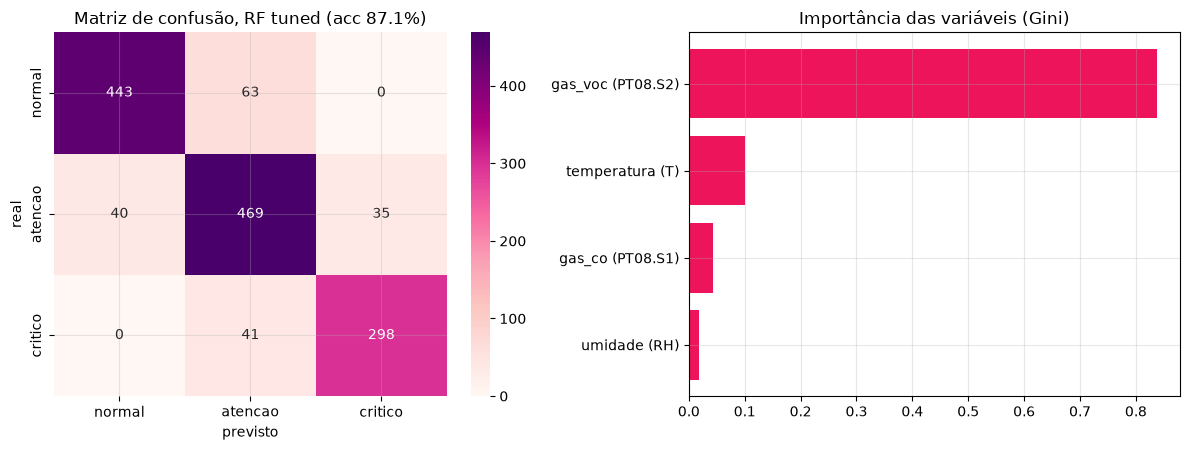

,feature,rotulo,importance
1,PT08.S2(NMHC),gas_voc (PT08.S2),0.837040
2,T,temperatura (T),0.100217
0,PT08.S1(CO),gas_co (PT08.S1),0.043998
3,RH,umidade (RH),0.018745


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
cm = confusion_matrix(y_test, best_te_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="RdPu", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title(f"Matriz de confusão, RF tuned (acc {tuned_row['test_acc']:.1%})")
axes[0].set_xlabel("previsto")
axes[0].set_ylabel("real")

FEATURE_LABELS = ["gas_co (PT08.S1)", "gas_voc (PT08.S2)", "temperatura (T)", "umidade (RH)"]
importances = best_pipe.named_steps["model"].feature_importances_
imp_df = pd.DataFrame({"feature": FEATURES, "rotulo": FEATURE_LABELS, "importance": importances})
imp_df = imp_df.sort_values("importance")
axes[1].barh(imp_df["rotulo"], imp_df["importance"], color="#ED145B")
axes[1].set_title("Importância das variáveis (Gini)")
fig.tight_layout()
fig.savefig(CHARTS_DIR / "02_confusao_feature_importance.png", dpi=150)
plt.show()
imp_df.sort_values("importance", ascending=False)

## 7. Por que 4 sensores e não 11

A base UCI tem 11 variáveis, mas 3 delas (C6H6, NOx, NO2) vêm de analisadores de referência que custam dezenas de milhares de reais. Nenhum nó comunitário tem isso. Por isso comparamos três opções com o mesmo split:

1. Regra do ESP32: só o sensor gas_voc com os limiares 830/1140. Roda offline no microcontrolador.
2. Modelo de campo: Random Forest tuned com as 4 leituras do ESP32. Roda na API.
3. Modelo de laboratório: mesmo Random Forest com as 11 variáveis. Só funcionaria com uma estação oficial.

In [7]:
def regra_esp32(voc):
    return (voc >= VOC_ATENCAO).astype(int) + (voc >= VOC_CRITICO).astype(int)

voc_test = df["PT08.S2(NMHC)"].to_numpy()[idx_test]
regra_pred = regra_esp32(voc_test)

X_lab = df[LAB_FEATURES].to_numpy(dtype=np.float32)
lab_pipe = pipe(RandomForestClassifier(random_state=42, n_jobs=-1))
lab_pipe.set_params(**search.best_params_)
lab_pipe.fit(X_lab[idx_train], y_train)
lab_pred = lab_pipe.predict(X_lab[idx_test])

def resumo(nome, pred):
    return {
        "conjunto": nome,
        "accuracy": round(float(accuracy_score(y_test, pred)), 4),
        "f1_macro": round(float(f1_score(y_test, pred, average="macro")), 4),
    }

conjuntos = [
    resumo("Regra do ESP32 (gas_voc 830/1140)", regra_pred),
    resumo("Modelo de campo (4 sensores do ESP32)", best_te_pred),
    resumo("Modelo de laboratório (11 variáveis UCI)", lab_pred),
]
conj_df = pd.DataFrame(conjuntos)
conj_df

,conjunto,accuracy,f1_macro
0,Regra do ESP32 (gas_voc 830/1140),0.8395,0.8430
1,Modelo de campo (4 sensores do ESP32),0.8711,0.8742
2,Modelo de laboratório (11 variáveis UCI),0.8826,0.8851


In [8]:
ganho_ia = conjuntos[1]["f1_macro"] - conjuntos[0]["f1_macro"]
perda_lab = conjuntos[2]["f1_macro"] - conjuntos[1]["f1_macro"]
print(f"Modelo de campo vs regra do ESP32: {ganho_ia:+.3f} de F1-macro")
print(f"Modelo de laboratório vs modelo de campo: {perda_lab:+.3f} de F1-macro")

Modelo de campo vs regra do ESP32: +0.031 de F1-macro
Modelo de laboratório vs modelo de campo: +0.011 de F1-macro


Ficamos com o modelo de campo. Ele perde pouco para o de laboratório, ganha da regra simples e, principalmente, roda com o que o ESP32 de fato mede. Um modelo melhor que exige um equipamento que ninguém na comunidade tem não ajuda ninguém. A regra fica no ESP32 porque precisa funcionar sem internet; o modelo entra quando a leitura chega à API.

## 8. Checagem honesta: split temporal

Horas vizinhas são quase iguais. No split aleatório, a hora 10h pode cair no treino e a 11h no teste, e isso infla a nota. Para medir esse efeito, treinamos com os primeiros 80% do período e testamos nos 20% finais, que o modelo nunca viu.

In [9]:
ordem = np.argsort(df["datahora"].to_numpy())
corte = int(len(ordem) * 0.8)
tr_t, te_t = ordem[:corte], ordem[corte:]
temporal_pipe = pipe(RandomForestClassifier(random_state=42, n_jobs=-1))
temporal_pipe.set_params(**search.best_params_)
temporal_pipe.fit(X[tr_t], y[tr_t])
temporal_pred = temporal_pipe.predict(X[te_t])
split_temporal_f1 = round(float(f1_score(y[te_t], temporal_pred, average="macro")), 4)
split_temporal_acc = round(float(accuracy_score(y[te_t], temporal_pred)), 4)
print(f"Treino até {df['datahora'].iloc[ordem[corte-1]]:%d/%m/%Y}, teste depois disso")
print(f"Split temporal: acc {split_temporal_acc} | F1-macro {split_temporal_f1}")
print(f"Split aleatório: acc {tuned_row['test_acc']} | F1-macro {tuned_row['test_f1_macro']}")

Treino até 30/01/2005, teste depois disso
Split temporal: acc 0.8452 | F1-macro 0.8487
Split aleatório: acc 0.8711 | F1-macro 0.8742


## 9. Exportação e previsões em leituras novas

Salvamos o Pipeline (scaler + Random Forest) em artifacts/best_ml_model.joblib. A API carrega esse arquivo e chama predict_proba com as 4 leituras na ordem gas_co, gas_voc, temperatura_c, umidade_pct.

In [10]:
joblib.dump(best_pipe, ARTIFACTS_DIR / "best_ml_model.joblib", compress=3)

unseen_samples = [
    {"cenario": "Manhã limpa perto da UBS", "entrada": [925.0, 706.0, 18.0, 55.0]},
    {"cenario": "Trânsito pesado no fim da tarde", "entrada": [1120.0, 980.0, 24.0, 42.0]},
    {"cenario": "Fumaça de queimada perto da escola", "entrada": [1383.0, 1280.0, 31.0, 34.0]},
]
demo_results = []
for sc in unseen_samples:
    probs = best_pipe.predict_proba(np.array([sc["entrada"]], dtype=np.float32))[0]
    item = {
        "cenario": sc["cenario"],
        "entrada": dict(zip(["gas_co", "gas_voc", "temperatura_c", "umidade_pct"], sc["entrada"])),
        "classe_predita": CLASS_NAMES[int(np.argmax(probs))],
        "probabilidades": {CLASS_NAMES[i]: round(float(probs[i]), 4) for i in range(3)},
    }
    demo_results.append(item)
    print(item["cenario"], "->", item["classe_predita"], item["probabilidades"])

metrics_payload = {
    "dataset": "UCI Air Quality (N = 6.941)",
    "features": FEATURES,
    "features_json": ["gas_co", "gas_voc", "temperatura_c", "umidade_pct"],
    "algoritmo_vencedor": "RandomForestClassifier (tuned)",
    "melhores_hiperparametros": search.best_params_,
    "cv_f1_macro": round(float(search.best_score_), 4),
    "teste_accuracy": tuned_row["test_acc"],
    "teste_f1_macro": tuned_row["test_f1_macro"],
    "comparacao_modelos": comp_df.to_dict(orient="records") + [tuned_row],
    "comparacao_conjuntos": conjuntos,
    "split_temporal_f1": split_temporal_f1,
    "split_temporal_accuracy": split_temporal_acc,
    "regra_esp32": {"metrica": "gas_voc", "atencao": VOC_ATENCAO, "critico": VOC_CRITICO},
    "feature_importance": imp_df.sort_values("importance", ascending=False)[["feature", "importance"]].round(4).to_dict(orient="records"),
    "matriz_confusao": cm.tolist(),
    "demonstracao_nao_vista": demo_results,
}
(ARTIFACTS_DIR / "ml_metrics.json").write_text(
    json.dumps(metrics_payload, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Modelo e métricas salvos em packages/ml-modelling/artifacts/")

Manhã limpa perto da UBS -> normal {'normal': 0.9987, 'atencao': 0.0013, 'critico': 0.0}
Trânsito pesado no fim da tarde -> atencao {'normal': 0.0401, 'atencao': 0.9515, 'critico': 0.0084}


Fumaça de queimada perto da escola -> critico {'normal': 0.0, 'atencao': 0.0683, 'critico': 0.9317}
Modelo e métricas salvos em packages/ml-modelling/artifacts/


## 10. Leitura dos resultados

- O Random Forest tuned (250 árvores, profundidade 8, folha mínima 16) chega a F1-macro 0,874 no teste e 0,870 na validação cruzada. Os dois números são próximos, então a busca não escolheu um modelo que só funciona naquele split.
- Contra a regra do ESP32 (F1 0,843) o modelo ganha 3 pontos. Contra o modelo de laboratório (0,885) perde 1 ponto. Aceitamos perder esse ponto para rodar com sensores que um nó comunitário consegue ter.
- No split temporal o F1 cai para 0,849. Esse é o número que esperamos na rua. O split aleatório infla a nota em uns 2,5 pontos.
- Os três cenários novos caem na classe esperada com probabilidade acima de 93%.
- Limite: a base é de uma cidade italiana entre 2004 e 2005. Para usar em São Paulo é preciso calibrar com leituras locais.